# Module 11 — Exercises — Solutions

These exercises follow the order of the concept guide: the likelihood and analytic MLEs, Fisher information,
numerical MLE, loss functions as negative log-likelihoods, conjugate posteriors, MAP as regularisation, the
posterior predictive, Bayesian A/B testing, and finally empirical-Bayes shrinkage. Several checks compare
your answer against a *hidden* value, so derive carefully rather than guessing.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb
from scipy import stats, optimize, special
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — The Bernoulli log-likelihood and its maximiser  `★☆☆`

For $k$ successes in $n$ independent Bernoulli trials the log-likelihood (dropping the binomial coefficient,
which does not depend on $p$) is $\ell(p) = k\log p + (n - k)\log(1 - p)$. Implement

* `bernoulli_loglik(p, k, n)` — $\ell(p)$; `p` may be a float or a NumPy array (return an array of the same shape);
* `mle_bernoulli(k, n)` — the maximiser $\hat p$ (derive it by setting $\ell'(p) = 0$; do not search numerically);
* `log_lik_ratio(p1, p2, k, n)` — $\ell(p_1) - \ell(p_2)$ as a float, the log of the likelihood ratio.

Use only NumPy (`np.log`).

In [3]:
def bernoulli_loglik(p, k, n):
    p = np.asarray(p, dtype=float)
    return k * np.log(p) + (n - k) * np.log(1 - p)

def mle_bernoulli(k, n):
    return k / n

def log_lik_ratio(p1, p2, k, n):
    return float(bernoulli_loglik(p1, k, n) - bernoulli_loglik(p2, k, n))

**Check your answer:**

In [4]:
try:
    got = bernoulli_loglik(0.5, 7, 10)
except Exception:
    got = None
check_close('log-likelihood at p = 0.5 for 7/10 is 10 log(0.5)', got, 10 * np.log(0.5))
try:
    arr = bernoulli_loglik(np.linspace(0.01, 0.99, 99), 7, 10)
    ok_shape = np.shape(arr) == (99,)
    argmax_p = float(np.linspace(0.01, 0.99, 99)[np.argmax(arr)]) if ok_shape else None
except Exception:
    ok_shape, argmax_p = False, None
check('vectorised over an array of p', ok_shape)
check_close('the grid maximum is at p = 0.70', argmax_p, 0.70, tol=1e-9)
try:
    got = mle_bernoulli(7, 10)
except Exception:
    got = None
check_close('MLE of 7/10 is 0.7', got, 0.7)
try:
    got = log_lik_ratio(0.7, 0.5, 7, 10)
except Exception:
    got = None
check_hash('log likelihood ratio 0.7 vs 0.5 for 7 heads in 10', got, '848375abd3971085')
try:
    got = log_lik_ratio(0.7, 0.5, 70, 100)
except Exception:
    got = None
check_hash('log likelihood ratio 0.7 vs 0.5 for 70 heads in 100', got, '6d1d21a7d2c5af98')

✅ log-likelihood at p = 0.5 for 7/10 is 10 log(0.5)
✅ vectorised over an array of p
✅ the grid maximum is at p = 0.70
✅ MLE of 7/10 is 0.7
✅ log likelihood ratio 0.7 vs 0.5 for 7 heads in 10
✅ log likelihood ratio 0.7 vs 0.5 for 70 heads in 100


True

**Why this works**

$\ell'(p) = k/p - (n-k)/(1-p) = 0$ gives $k(1-p) = (n-k)p$, i.e. $\hat p = k/n$ — the sample proportion.
The binomial coefficient is a constant in $p$ and cancels in every ratio, which is why it can be dropped.
The log likelihood ratio grows linearly with the data: ten times the flips at the same proportion gives ten
times the log-ratio ($0.823 \to 8.23$), turning weak evidence into overwhelming evidence. A common slip is
to compute the *difference* of likelihoods rather than of log-likelihoods, or to divide by $n$ — the
likelihood ratio is a ratio of total probabilities, not of averages.

## Exercise 2 — Derive and code the Exponential MLE  `★☆☆`

Waiting times $x_1, \dots, x_n$ follow an Exponential distribution with rate $\lambda$, density
$f(x) = \lambda e^{-\lambda x}$. Derive the log-likelihood, set its derivative to zero, and implement

* `exp_loglik(lam, x)` — $\ell(\lambda)$ for an array `x`, as a float;
* `mle_exponential(x)` — $\hat\lambda$ as a float (closed form, no optimiser);
* `mle_tail_prob(x, t)` — the MLE of $P(X > t) = e^{-\lambda t}$, using the invariance property.

Test data: `x = np.array([2.0, 0.5, 1.5, 4.0])` and `t = 3.0`. The second hidden check draws 400 waiting
times with `rng.exponential(scale=1/2.5, size=400)` from a fresh `np.random.default_rng(0)`.

In [5]:
def mle_exponential(x):
    x = np.asarray(x, dtype=float)
    return float(len(x) / x.sum())

def exp_loglik(lam, x):
    x = np.asarray(x, dtype=float)
    return float(len(x) * np.log(lam) - lam * x.sum())

def mle_tail_prob(x, t):
    return float(np.exp(-mle_exponential(x) * t))

**Check your answer:**

In [6]:
x_rep = np.array([2.0, 0.5, 1.5, 4.0])
try:
    got = mle_exponential(x_rep)
except Exception:
    got = None
check_close('MLE rate for the repair times is 1/mean = 0.5', got, 0.5)
try:
    got = mle_tail_prob(x_rep, 3.0)
except Exception:
    got = None
check_hash('MLE of P(X > 3) by invariance', got, '09184c69b2341ec7', decimals=4)
try:
    ll0 = exp_loglik(0.5, x_rep); ll1 = exp_loglik(0.55, x_rep); ll2 = exp_loglik(0.45, x_rep)
    ok_max = (ll0 is not None) and ll0 > ll1 and ll0 > ll2
except Exception:
    ok_max = False
check('the log-likelihood is larger at the MLE than 10% either side', ok_max)
try:
    got = exp_loglik(0.5, x_rep)
except Exception:
    got = None
check_close('log-likelihood at lambda = 0.5 equals 4 log 0.5 - 4', got, 4 * np.log(0.5) - 4.0)
rng = np.random.default_rng(0)
x_big = rng.exponential(scale=1/2.5, size=400)
try:
    got = mle_exponential(x_big)
except Exception:
    got = None
check_hash('MLE rate for the 400 simulated waiting times', got, '4d8508a3d2fec0b7', decimals=3)
check('that estimate is within 3 standard errors (3 x 2.5/sqrt(400) = 0.375) of the true rate 2.5', (got is not None) and abs(got - 2.5) < 0.375)

✅ MLE rate for the repair times is 1/mean = 0.5
✅ MLE of P(X > 3) by invariance
✅ the log-likelihood is larger at the MLE than 10% either side
✅ log-likelihood at lambda = 0.5 equals 4 log 0.5 - 4
✅ MLE rate for the 400 simulated waiting times
✅ that estimate is within 3 standard errors (3 x 2.5/sqrt(400) = 0.375) of the true rate 2.5


True

**Why this works**

$\ell(\lambda) = \sum_i [\log\lambda - \lambda x_i] = n\log\lambda - \lambda\sum_i x_i$, so
$\ell'(\lambda) = n/\lambda - \sum_i x_i = 0$ gives $\hat\lambda = n/\sum x_i = 1/\bar x$; the second
derivative $-n/\lambda^2 < 0$ confirms a maximum. For the repair times $\bar x = 2$, $\hat\lambda = 0.5$.
Invariance says the MLE of any function of $\lambda$ is that function of $\hat\lambda$, so
$\widehat{P}(X > 3) = e^{-1.5} \approx 0.223$ needs no new optimisation. The simulated sample gives
$\hat\lambda \approx 2.22$, which happens to be 2.25 standard errors low ($\operatorname{SE} = \lambda/\sqrt{n} = 0.125$):
an estimate is not the truth, even with 400 points. The usual wrong turn is to estimate the *mean* $1/\lambda$
and forget to invert, or to use $\bar x$ itself as the rate.

## Exercise 3 — Fisher information and a Wald interval for a Poisson rate  `★★☆`

For a single Poisson count $x$ with rate $\lambda$, $\log p(x \mid \lambda) = x\log\lambda - \lambda - \log x!$.
Derive the Fisher information $i(\lambda) = -\mathbb{E}[\partial^2_\lambda \log p]$ by hand, then implement

* `fisher_info_poisson(lam, n)` — $I_n(\lambda) = n\,i(\lambda)$ for $n$ i.i.d. counts, as a float;
* `poisson_mle_se(x)` — a tuple `(lam_hat, se)` with the MLE and its standard error $1/\sqrt{I_n(\hat\lambda)}$;
* `wald_ci_poisson(x, z=1.96)` — the tuple `(lower, upper)` of the Wald interval $\hat\lambda \pm z\,\operatorname{SE}$;
* `observed_info_poisson(x)` — the observed information $J(\hat\lambda) = -\ell''(\hat\lambda)$ computed from the
  data (not from the expectation formula). For the Poisson it should coincide with $I_n(\hat\lambda)$.

Test data: the six hourly call counts `[3, 5, 2, 4, 6, 4]`. A second check uses 250 counts drawn with
`rng.poisson(7.0, size=250)` from a freshly seeded `np.random.default_rng(0)`.

In [7]:
def fisher_info_poisson(lam, n):
    return float(n / lam)

def poisson_mle_se(x):
    x = np.asarray(x, dtype=float)
    lam_hat = x.mean()
    return float(lam_hat), float(np.sqrt(lam_hat / len(x)))

def wald_ci_poisson(x, z=1.96):
    lam_hat, se = poisson_mle_se(x)
    return (lam_hat - z * se, lam_hat + z * se)

def observed_info_poisson(x):
    x = np.asarray(x, dtype=float)
    lam_hat = x.mean()
    return float(x.sum() / lam_hat**2)       # -l''(lam_hat) = sum(x)/lam^2

**Check your answer:**

In [8]:
calls = np.array([3, 5, 2, 4, 6, 4])
try:
    got = fisher_info_poisson(4.0, 6)
except Exception:
    got = None
check_close('I_6(lambda = 4) = 6/4 = 1.5', got, 1.5)
try:
    lam_hat, se = poisson_mle_se(calls)
except Exception:
    lam_hat, se = None, None
check_close('MLE for the call counts is 4.0', lam_hat, 4.0)
check_hash('standard error of the call-rate MLE', se, '213eb13b19246f1c', decimals=4)
try:
    lo, hi = wald_ci_poisson(calls)
except Exception:
    lo, hi = None, None
check_hash('upper end of the 95% Wald interval for the call rate', hi, 'b21f0796883ff372', decimals=3)
check_close('the interval is symmetric about the MLE', (None if lo is None else (lo + hi) / 2), 4.0)
try:
    got = observed_info_poisson(calls)
except Exception:
    got = None
check_close('observed information equals n/lambda_hat for the call counts', got, 6 / 4.0)
rng = np.random.default_rng(0)
counts_big = rng.poisson(7.0, size=250)
try:
    lo, hi = wald_ci_poisson(counts_big)
except Exception:
    lo, hi = None, None
check_hash('lower end of the 95% Wald interval for the 250 counts', lo, '3b9dd1bbe5d55f05', decimals=3)
check('that interval contains the true rate 7.0', (lo is not None) and lo < 7.0 < hi)

✅ I_6(lambda = 4) = 6/4 = 1.5
✅ MLE for the call counts is 4.0
✅ standard error of the call-rate MLE
✅ upper end of the 95% Wald interval for the call rate
✅ the interval is symmetric about the MLE
✅ observed information equals n/lambda_hat for the call counts
✅ lower end of the 95% Wald interval for the 250 counts
✅ that interval contains the true rate 7.0


True

**Why this works**

$\partial_\lambda \log p = x/\lambda - 1$ and $\partial^2_\lambda \log p = -x/\lambda^2$; taking the
expectation with $\mathbb{E}[x] = \lambda$ gives $i(\lambda) = 1/\lambda$, so $I_n = n/\lambda$ and
$\operatorname{SE}(\hat\lambda) = \sqrt{\hat\lambda/n}$ — for the calls, $\sqrt{4/6} = 0.816$ and a Wald
interval of $[2.40, 5.60]$. The observed information is $-\ell''(\hat\lambda) = \sum x_i/\hat\lambda^2 =
n\bar x/\bar x^2 = n/\bar x$, identical to $I_n(\hat\lambda)$ because the Poisson's second derivative depends
on the data only through $\sum x_i$. (Only six counts, so the interval is wide. For very small counts, such as
`[0, 0, 1, 0, 0, 0]`, the Wald interval goes negative ($-0.16$), which the Gamma posterior of the guide's
Section 7 never does.) A frequent error is to forget the $n$: the information for one count is
$1/\lambda$, for $n$ counts $n/\lambda$.

## Exercise 4 — Numerical MLE for the Gamma distribution  `★★☆`

The Gamma$(\alpha, \beta)$ density (shape $\alpha$, **rate** $\beta$) is
$f(x) = \frac{\beta^\alpha}{\Gamma(\alpha)}x^{\alpha - 1}e^{-\beta x}$, so for a sample $x_1, \dots, x_n$

$$\ell(\alpha, \beta) = n\alpha\log\beta - n\log\Gamma(\alpha) + (\alpha - 1)\sum_i\log x_i - \beta\sum_i x_i .$$

There is no closed form for $\hat\alpha$. Implement

* `gamma_nll(theta, x)` — the **negative** log-likelihood as a float, where `theta = (log_alpha, log_beta)` are
  the *logarithms* of the parameters (so the optimiser can roam over all of $\mathbb{R}^2$). Use
  `scipy.special.gammaln` for $\log\Gamma$.
* `fit_gamma_mle(x)` — returns the tuple `(alpha_hat, beta_hat)` by minimising `gamma_nll` with
  `scipy.optimize.minimize` (any method; a method-of-moments start $\alpha_0 = \bar x^2/\hat\sigma^2$,
  $\beta_0 = \alpha_0/\bar x$ is a good idea).

Checks compare with the guide's hand-worked five-point example and with `scipy.stats.gamma.fit(x, floc=0)`
(which returns `shape, loc, scale` with `scale = 1/beta`) on 300 points drawn via
`rng.gamma(shape=2.5, scale=1/1.5, size=300)` from a fresh `np.random.default_rng(0)`.

In [9]:
def gamma_nll(theta, x):
    log_a, log_b = theta
    a, b = np.exp(log_a), np.exp(log_b)
    x = np.asarray(x, dtype=float)
    return float(-(len(x) * a * np.log(b) - len(x) * special.gammaln(a) + (a - 1) * np.log(x).sum() - b * x.sum()))

def fit_gamma_mle(x):
    x = np.asarray(x, dtype=float)
    # method-of-moments start, in log-parameters
    a0 = x.mean()**2 / x.var(); b0 = a0 / x.mean()
    res = optimize.minimize(gamma_nll, x0=np.log([a0, b0]), args=(x,), method="BFGS")
    a_hat, b_hat = np.exp(res.x)
    return float(a_hat), float(b_hat)

**Check your answer:**

In [10]:
x_small = np.array([1.2, 2.5, 0.8, 3.1, 1.9])
try:
    got = gamma_nll(np.log([2.0, 1.0]), x_small)
except Exception:
    got = None
check_close('NLL at alpha = 2, beta = 1 equals -sum(log x) + sum(x)', got, float(-(np.log(x_small).sum()) + x_small.sum()), tol=1e-6)
try:
    a_s, b_s = fit_gamma_mle(x_small)
except Exception:
    a_s, b_s = None, None
check_close("shape MLE for the guide's five points is 4.620", a_s, 4.6201, tol=2e-3)
check_close('rate MLE equals shape / mean', (None if a_s is None else b_s), (None if a_s is None else a_s / x_small.mean()), tol=2e-3)
rng = np.random.default_rng(0)
x_sim = rng.gamma(shape=2.5, scale=1/1.5, size=300)
try:
    a_hat, b_hat = fit_gamma_mle(x_sim)
    a_sp, _, scale_sp = stats.gamma.fit(x_sim, floc=0)
except Exception:
    a_hat, b_hat, a_sp, scale_sp = None, None, 1.0, 1.0
check_close('shape agrees with scipy.stats.gamma.fit', a_hat, a_sp, tol=1e-3)
check_close('rate agrees with 1/scale from scipy', b_hat, 1 / scale_sp, tol=1e-3)
try:
    nll_mle = gamma_nll(np.log([a_hat, b_hat]), x_sim)
    nll_off = gamma_nll(np.log([a_hat * 1.2, b_hat]), x_sim)
    ok = nll_mle < nll_off
except Exception:
    ok = False
check('the NLL is lower at the fitted parameters than at a perturbed shape', ok)

✅ NLL at alpha = 2, beta = 1 equals -sum(log x) + sum(x)
✅ shape MLE for the guide's five points is 4.620
✅ rate MLE equals shape / mean
✅ shape agrees with scipy.stats.gamma.fit
✅ rate agrees with 1/scale from scipy
✅ the NLL is lower at the fitted parameters than at a perturbed shape


True

**Why this works**

Working in $(\log\alpha, \log\beta)$ turns a constrained problem into an unconstrained one, so BFGS never
tries a negative shape. The NLL is smooth and convex in $\log\beta$ for fixed $\alpha$, and the profile in
$\alpha$ is unimodal, so any reasonable start converges — the method-of-moments start just saves iterations.
`scipy.stats.gamma.fit(x, floc=0)` solves the same problem (with `loc` fixed at 0, as our model assumes),
which is why the two agree to about $10^{-6}$; without `floc=0` scipy would also fit a shift parameter and
land somewhere else. Forgetting `gammaln` and using `np.log(special.gamma(a))` overflows for $a \gtrsim 170$;
forgetting the $n$ in $n\alpha\log\beta$ and $n\log\Gamma(\alpha)$ is the classic bookkeeping bug.

## Exercise 5 — Cross-entropy is the negative log-likelihood of the labels  `★★☆`

Build the classification losses *from the likelihood*, not from a formula you remember:

* `bce_from_likelihood(y, p)` — for binary labels `y` and predicted probabilities `p`, compute the Bernoulli
  likelihood of each label, $p_i^{y_i}(1 - p_i)^{1 - y_i}$, take logs, and return $-\frac1n\sum_i \log(\cdot)$
  as a float. It must equal the binary cross-entropy.
* `softmax(z)` — row-wise softmax of a 2-D array of logits (subtract the row maximum first for stability).
* `categorical_nll(logits, labels)` — for an $n \times K$ array of logits and integer `labels` in $\{0, \dots, K-1\}$,
  return $-\frac1n\sum_i \log \text{softmax}(z_i)_{y_i}$ as a float.
* `ce_grad_logits(logits, labels)` — the gradient of `categorical_nll` with respect to the logits, an $n \times K$
  array. Derive it: for the mean loss it is $(p_i - \mathbf{e}_{y_i})/n$ in row $i$.

Use only NumPy. The checks compare with `sklearn.metrics.log_loss` and with a finite-difference gradient.

In [11]:
def bce_from_likelihood(y, p):
    y = np.asarray(y, dtype=float); p = np.asarray(p, dtype=float)
    lik = p**y * (1 - p)**(1 - y)            # Bernoulli p(y_i | p_i)
    return float(-np.mean(np.log(lik)))

def softmax(z):
    z = np.asarray(z, dtype=float)
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

def categorical_nll(logits, labels):
    p = softmax(logits)
    labels = np.asarray(labels)
    return float(-np.mean(np.log(p[np.arange(len(labels)), labels])))

def ce_grad_logits(logits, labels):
    p = softmax(logits)
    onehot = np.zeros_like(p)
    onehot[np.arange(len(labels)), labels] = 1.0
    return (p - onehot) / len(labels)

**Check your answer:**

In [12]:
from sklearn.metrics import log_loss
y_demo = np.array([1, 0, 1, 1, 0]); p_demo = np.array([0.9, 0.2, 0.6, 0.3, 0.1])
try:
    got = bce_from_likelihood(y_demo, p_demo)
except Exception:
    got = None
check_close('BCE from the Bernoulli likelihood equals sklearn log_loss', got, log_loss(y_demo, p_demo), tol=1e-9)
try:
    got = bce_from_likelihood(np.array([1, 1]), np.array([0.5, 0.5]))
except Exception:
    got = None
check_close('two labels at p = 0.5 cost log 2 each', got, np.log(2.0))
logits = np.array([[2.0, 1.0, 0.1], [0.5, 2.5, -1.0], [1.0, 1.0, 1.0], [-1.0, 0.0, 3.0]])
labels = np.array([0, 1, 2, 1])
try:
    sm = softmax(logits)
    ok_rows = np.allclose(sm.sum(axis=1), 1.0) and sm.shape == (4, 3) and np.all(sm > 0)
except Exception:
    ok_rows = False
check('softmax rows are positive and sum to 1', ok_rows)
try:
    got = categorical_nll(logits, labels)
except Exception:
    got = None
check_close('categorical NLL equals sklearn log_loss on the softmax probabilities', got, (log_loss(labels, softmax(logits), labels=[0, 1, 2]) if ok_rows else None), tol=1e-9)
check_hash('categorical NLL of the four examples', got, 'b84896071eba5d87', decimals=4)
try:
    g = ce_grad_logits(logits, labels)
    eps = 1e-6; g_fd = np.zeros_like(logits)
    for i in range(logits.shape[0]):
        for j in range(logits.shape[1]):
            d = np.zeros_like(logits); d[i, j] = eps
            g_fd[i, j] = (categorical_nll(logits + d, labels) - categorical_nll(logits - d, labels)) / (2 * eps)
    ok_grad = g.shape == (4, 3) and np.allclose(g, g_fd, atol=1e-6)
    ok_rowsum = np.allclose(g.sum(axis=1), 0.0, atol=1e-12)
except Exception:
    ok_grad, ok_rowsum = False, False
check('analytic gradient (p - y)/n matches finite differences', ok_grad)
check('each row of the gradient sums to zero', ok_rowsum)
try:
    got = float(ce_grad_logits(logits, labels)[3, 1])
except Exception:
    got = None
check_hash('gradient entry for example 4, true class 1', got, '712660d7fa1c3bdf', decimals=4)

✅ BCE from the Bernoulli likelihood equals sklearn log_loss
✅ two labels at p = 0.5 cost log 2 each
✅ softmax rows are positive and sum to 1
✅ categorical NLL equals sklearn log_loss on the softmax probabilities
✅ categorical NLL of the four examples
✅ analytic gradient (p - y)/n matches finite differences
✅ each row of the gradient sums to zero
✅ gradient entry for example 4, true class 1


True

**Why this works**

Writing $p(y_i \mid p_i) = p_i^{y_i}(1 - p_i)^{1 - y_i}$ and taking the log gives
$y_i\log p_i + (1 - y_i)\log(1 - p_i)$ — the negative mean of this *is* binary cross-entropy, so the two
functions agree to machine precision. For $K$ classes the likelihood of the label is the softmax probability
of the true class, and its negative log is the cross-entropy with a one-hot target. The gradient is the
famous $p - y$: because $\partial\log\text{softmax}(z)_y/\partial z_j = \mathbf{1}[j = y] - p_j$, each row of
the gradient is $(p_i - \mathbf{e}_{y_i})/n$, which sums to zero, because adding the same constant to every
logit leaves the softmax, and hence the loss, unchanged. Subtracting the row maximum before `exp` prevents overflow and does not change the softmax, since
the shift cancels in the ratio. The common bug is forgetting the $1/n$ in the gradient after averaging the
loss, which the finite-difference check catches.

## Exercise 6 — Beta-Binomial posterior, posterior mean and credible interval  `★★☆`

Implement the conjugate update for a success probability:

* `beta_posterior(a, b, k, n)` — the tuple `(a_post, b_post)` of the posterior Beta parameters after $k$
  successes in $n$ trials with a Beta$(a, b)$ prior;
* `beta_posterior_summary(a, b, k, n, level=0.95)` — a dict with keys `a`, `b`, `mean` (posterior mean) and
  `lower`, `upper` (the equal-tailed `level` credible interval, via `scipy.stats.beta.ppf`);
* `prob_rate_above(a, b, k, n, threshold)` — $P(p > \text{threshold} \mid \mathcal{D})$ as a float.

Test cases: (i) uniform prior, 2 clicks in 40 impressions; (ii) Beta$(2, 8)$ prior, 7 heads in 10;
(iii) the surgeon from the guide — Beta$(5, 95)$ prior, 2 complications in 15 operations.

In [13]:
def beta_posterior(a, b, k, n):
    return (a + k, b + n - k)

def beta_posterior_summary(a, b, k, n, level=0.95):
    a_post, b_post = beta_posterior(a, b, k, n)
    post = stats.beta(a_post, b_post)
    mean = a_post / (a_post + b_post)
    alpha = (1 - level) / 2
    lo, hi = post.ppf(alpha), post.ppf(1 - alpha)
    return dict(a=a_post, b=b_post, mean=float(mean), lower=float(lo), upper=float(hi))

def prob_rate_above(a, b, k, n, threshold):
    a_post, b_post = beta_posterior(a, b, k, n)
    return float(1 - stats.beta.cdf(threshold, a_post, b_post))

**Check your answer:**

In [14]:
try:
    got = beta_posterior(1, 1, 2, 40)
except Exception:
    got = None
check('uniform prior + 2/40 gives Beta(3, 39)', got is not None and tuple(got) == (3, 39))
try:
    s = beta_posterior_summary(1, 1, 2, 40)
    mean, lo, hi = s["mean"], s["lower"], s["upper"]
except Exception:
    mean, lo, hi = None, None, None
check_close('posterior mean 3/42', mean, 3/42)
check_hash('upper end of the 95% credible interval (2 in 40, uniform prior)', hi, '2c98d172582a8634', decimals=4)
check('the interval is inside [0, 1] and contains the posterior mean', (lo is not None) and 0 < lo < mean < hi < 1)
try:
    s = beta_posterior_summary(2, 8, 7, 10)
    got = s["mean"]
except Exception:
    got = None
check_close('Beta(2,8) prior + 7/10 -> mean 0.45', got, 0.45)
try:
    s = beta_posterior_summary(5, 95, 2, 15)
    got = s["mean"]
except Exception:
    got = None
check_hash('shrunken complication rate of the surgeon (Beta(5,95) prior, 2 in 15)', got, '7551fe1e128c1b0a', decimals=4)
try:
    got = prob_rate_above(1, 1, 2, 40, 0.10)
except Exception:
    got = None
check_hash('P(p > 0.10 | 2 clicks in 40, uniform prior)', got, '4eb83c23e3c4dcf9', decimals=3)
try:
    got = prob_rate_above(5, 95, 20, 150, 0.08)
except Exception:
    got = None
check_hash('P(rate > 8%) for the surgeon with 20 complications in 150', got, '2c3b2e9841dcb3e3', decimals=3)

✅ uniform prior + 2/40 gives Beta(3, 39)
✅ posterior mean 3/42
✅ upper end of the 95% credible interval (2 in 40, uniform prior)
✅ the interval is inside [0, 1] and contains the posterior mean
✅ Beta(2,8) prior + 7/10 -> mean 0.45
✅ shrunken complication rate of the surgeon (Beta(5,95) prior, 2 in 15)
✅ P(p > 0.10 | 2 clicks in 40, uniform prior)
✅ P(rate > 8%) for the surgeon with 20 complications in 150


True

**Why this works**

Multiplying the Beta$(a, b)$ kernel $p^{a-1}(1-p)^{b-1}$ by the Binomial kernel $p^k(1-p)^{n-k}$ gives
$p^{a+k-1}(1-p)^{b+n-k-1}$, the kernel of Beta$(a + k, b + n - k)$ — the whole update is two additions. The
posterior mean $\frac{a+k}{a+b+n}$ is the data proportion pulled toward the prior mean with weight
$\frac{a+b}{a+b+n}$: for the surgeon, $7/115 = 6.1\%$ instead of the raw $13.3\%$, because 100 pseudo-cases
outweigh 15 real ones. Credible intervals come straight from the Beta quantiles and can never leave $[0, 1]$,
unlike the Wald interval. A typical error is to add $n$ to the second parameter instead of $n - k$ — the
prior failures plus the observed failures, not the total trials.

## Exercise 7 — Normal-Normal updating: precisions add  `★★☆`

A quantity $\mu$ has prior $\mathcal{N}(\mu_0, \tau^2)$; observations $x_i \sim \mathcal{N}(\mu, \sigma^2)$ with
**known** $\sigma^2$. Implement

* `normal_normal_posterior(mu0, tau2, sigma2, x)` — returns `(mu_post, var_post)` for the array `x`, using the
  precision form $\frac{1}{\sigma_n^2} = \frac{1}{\tau^2} + \frac{n}{\sigma^2}$,
  $\mu_n = \sigma_n^2\big(\frac{\mu_0}{\tau^2} + \frac{\sum_i x_i}{\sigma^2}\big)$;
* `sequential_normal_update(mu0, tau2, sigma2, x)` — the same posterior obtained by updating **one observation at
  a time**, feeding each posterior in as the next prior; it must return the same `(mu_post, var_post)`.

Test case: prior $\mathcal{N}(100, 10^2)$, sensor noise $\sigma = 4$, readings `[106.0, 110.5, 107.2, 108.3]`.
A second check uses 25 draws `rng.normal(1.5, 2.0, size=25)` from a fresh `np.random.default_rng(0)` with prior
$\mathcal{N}(0, 1)$ and $\sigma^2 = 4$.

In [15]:
def normal_normal_posterior(mu0, tau2, sigma2, x):
    x = np.asarray(x, dtype=float)
    n = len(x)
    prec_post = 1 / tau2 + n / sigma2
    mu_post = (mu0 / tau2 + x.sum() / sigma2) / prec_post
    return float(mu_post), float(1 / prec_post)

def sequential_normal_update(mu0, tau2, sigma2, x):
    mu, var = float(mu0), float(tau2)
    for xi in np.asarray(x, dtype=float):
        mu, var = normal_normal_posterior(mu, var, sigma2, [xi])
    return mu, var

**Check your answer:**

In [16]:
readings = np.array([106.0, 110.5, 107.2, 108.3])
try:
    mu_b, var_b = normal_normal_posterior(100.0, 100.0, 16.0, readings)
except Exception:
    mu_b, var_b = None, None
check_close('posterior variance 1/(0.01 + 0.25)', var_b, 1 / 0.26)
check_hash('posterior mean for the furnace readings', mu_b, '9f0a95988c6131dc', decimals=3)
check('posterior mean lies between the prior mean and the sample mean', (mu_b is not None) and 100.0 < mu_b < readings.mean())
try:
    mu_s, var_s = sequential_normal_update(100.0, 100.0, 16.0, readings)
except Exception:
    mu_s, var_s = None, None
check_close('sequential update gives the same mean as the batch update', mu_s, mu_b, tol=1e-9)
check_close('sequential update gives the same variance as the batch update', var_s, var_b, tol=1e-9)
rng = np.random.default_rng(0)
x25 = rng.normal(1.5, 2.0, size=25)
try:
    mu_c, var_c = normal_normal_posterior(0.0, 1.0, 4.0, x25)
except Exception:
    mu_c, var_c = None, None
check_hash('posterior mean for the 25 draws', mu_c, '3b07dd65a821c022', decimals=3)
check_close('posterior variance 1/(1 + 25/4)', var_c, 1 / (1 + 25 / 4))

✅ posterior variance 1/(0.01 + 0.25)
✅ posterior mean for the furnace readings
✅ posterior mean lies between the prior mean and the sample mean
✅ sequential update gives the same mean as the batch update
✅ sequential update gives the same variance as the batch update
✅ posterior mean for the 25 draws
✅ posterior variance 1/(1 + 25/4)


True

**Why this works**

The prior contributes precision $1/\tau^2 = 0.01$ and the four readings $n/\sigma^2 = 0.25$; the posterior
precision is their sum $0.26$ (variance $3.85$, sd $1.96$) and the posterior mean is the precision-weighted
average $(0.01 \cdot 100 + 0.25 \cdot 108)/0.26 = 107.7$ — 96% of the way to the data because the sensor is
far more informative than the prior. Updating one reading at a time gives exactly the same answer: each step
adds $1/\sigma^2$ to the precision and $x_i/\sigma^2$ to the weighted sum, and addition is associative. This
is the scalar Kalman filter's measurement update. The usual mistake is to average *variances* or to weight
by standard deviations instead of precisions.

## Exercise 8 — MAP with a Gaussian prior is ridge regression with lambda = sigma^2 / tau^2  `★★☆`

For $y = Xw + \varepsilon$, $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$, with prior $w_j \sim \mathcal{N}(0, \tau^2)$,
the guide derives $\hat w_{\text{MAP}} = \arg\min_w \|y - Xw\|^2 + \lambda\|w\|^2$ with $\lambda = \sigma^2/\tau^2$.
Implement, with NumPy only (`np.linalg.solve`, no scikit-learn inside the functions):

* `map_gaussian_prior(X, y, sigma2, tau2)` — the MAP weight vector via the closed form $(X^\top X + \lambda I)^{-1}X^\top y$;
* `mle_least_squares(X, y)` — the MLE / ordinary least-squares weights $(X^\top X)^{-1}X^\top y$.

The checks generate `X8 = rng.normal(size=(40, 6))`, `y8 = X8 @ w_true + rng.normal(0, 0.5, size=40)` with
`w_true = [2, -1, 0.5, 0, 0, 1.5]` from a fresh `np.random.default_rng(0)`, compare your MAP with
`Ridge(alpha=sigma2/tau2, fit_intercept=False)`, and verify two consequences: the MAP has a smaller norm than
the MLE, and stacking the data ten times (same prior) moves the MAP toward the MLE.

In [17]:
def map_gaussian_prior(X, y, sigma2, tau2):
    lam = sigma2 / tau2
    return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y)

def mle_least_squares(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

**Check your answer:**

In [18]:
from sklearn.linear_model import Ridge
rng = np.random.default_rng(0)
X8 = rng.normal(size=(40, 6)); w_true = np.array([2.0, -1.0, 0.5, 0.0, 0.0, 1.5])
y8 = X8 @ w_true + rng.normal(0, 0.5, size=40)
try:
    w_map = np.asarray(map_gaussian_prior(X8, y8, sigma2=0.25, tau2=0.01), dtype=float)
    w_mle = np.asarray(mle_least_squares(X8, y8), dtype=float)
    ok_shape = w_map.shape == (6,) and w_mle.shape == (6,)
except Exception:
    w_map, w_mle, ok_shape = None, None, False
check('both weight vectors have shape (6,)', ok_shape)
check_close('MAP equals Ridge(alpha = sigma^2/tau^2 = 25)', w_map, Ridge(alpha=25.0, fit_intercept=False).fit(X8, y8).coef_, tol=1e-8)
check_close('MLE equals np.linalg.lstsq', w_mle, np.linalg.lstsq(X8, y8, rcond=None)[0], tol=1e-8)
check('the MAP has a smaller norm than the MLE (shrinkage)', ok_shape and np.linalg.norm(w_map) < np.linalg.norm(w_mle))
check_hash('norm of the MAP weights', (float(np.linalg.norm(w_map)) if ok_shape else None), '283339cfe5eb32f6', decimals=3)
try:
    w_loose = map_gaussian_prior(X8, y8, sigma2=0.25, tau2=1e6)
    ok_loose = np.allclose(w_loose, w_mle, atol=1e-4)
except Exception:
    ok_loose = False
check('a very wide prior (tau^2 = 1e6) recovers the MLE', ok_loose)
try:
    X80 = np.vstack([X8] * 10); y80 = np.concatenate([y8] * 10)
    w_big = map_gaussian_prior(X80, y80, sigma2=0.25, tau2=0.01)
    ok_big = np.linalg.norm(w_big - w_mle) < np.linalg.norm(w_map - w_mle)
except Exception:
    ok_big = False
check('ten times the data, same prior: the MAP moves toward the MLE', ok_big)

✅ both weight vectors have shape (6,)
✅ MAP equals Ridge(alpha = sigma^2/tau^2 = 25)
✅ MLE equals np.linalg.lstsq
✅ the MAP has a smaller norm than the MLE (shrinkage)
✅ norm of the MAP weights
✅ a very wide prior (tau^2 = 1e6) recovers the MLE
✅ ten times the data, same prior: the MAP moves toward the MLE


True

**Why this works**

$-\log p(w \mid \mathcal{D}) = \frac{1}{2\sigma^2}\|y - Xw\|^2 + \frac{1}{2\tau^2}\|w\|^2 + \text{const}$;
multiplying by $2\sigma^2$ gives the ridge objective with $\lambda = \sigma^2/\tau^2 = 0.25/0.01 = 25$, and
setting the gradient $-2X^\top(y - Xw) + 2\lambda w$ to zero gives the normal equations with $\lambda I$ added
— identical to what `Ridge` solves, hence agreement to $10^{-8}$. Shrinkage is visible in the smaller norm;
with $\tau^2 = 10^6$ the prior is flat and the MAP collapses onto the MLE. Stacking the data ten times
multiplies $X^\top X$ and $X^\top y$ by ten while $\lambda I$ stays put, so the prior's share of the solution
drops tenfold: the same $\lambda$ regularises less on more data, which is the correct behaviour for a fixed
prior; only if your loss is a mean must the constant be divided by $n$. (Stacking copies is only a device to scale $n$ without changing the data's direction;
the point stands for genuinely new data.)

## Exercise 9 — Credible interval or confidence interval?  `★★☆`

A data scientist runs an experiment and reports: "The 95% confidence interval for the conversion rate is
$[4.1\%, 5.9\%]$. So there is a 95% probability that the true rate is between 4.1% and 5.9%." A colleague
replies: "You can only say that if you computed a credible interval — and then you'd have to tell me your
prior." Who is right? In your answer (a) explain precisely what the 95% in a confidence interval refers to,
(b) explain what a 95% credible interval claims and what it requires, (c) say under which circumstances the
two intervals are numerically almost identical, and (d) give one situation from this module where they differ
sharply and say which one you would trust.

**Answer**

The colleague is right about the logic, even if the numbers may be close. **(a)** A confidence interval is
the output of a *procedure*; "95%" is the long-run frequency with which that procedure captures the fixed,
unknown parameter over hypothetical repetitions of the experiment. Once the data are in and the interval is
$[4.1\%, 5.9\%]$, the parameter is either inside it or not — no probability attaches to this particular
interval. **(b)** A 95% credible interval $[a, b]$ satisfies $P(a \le \theta \le b \mid \mathcal{D}) = 0.95$,
a direct probability statement about the parameter *given these data*; it requires a prior, because without
one there is no posterior to take quantiles of. **(c)** With a flat (or weak) prior and a large sample, the
posterior is approximately $\mathcal{N}(\hat\theta, \operatorname{SE}^2)$ — the same normal that the Wald
interval is built from — so the two intervals nearly coincide numerically (for thousands of visitors, both
are about $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$). The sentence becomes *correct* if it is read as a
statement about the flat-prior posterior. **(d)** They differ sharply for small $n$ or rates near 0 or 1: for
2 clicks in 40 impressions the Wald interval is $[-1.8\%, 11.8\%]$ — it includes impossible negative rates
and understates the right tail — while the Beta$(3, 39)$ credible interval is $[1.5\%, 16.5\%]$. Here the
credible interval is the one to trust, because it is exact for any $n$ and respects the parameter space,
whereas the Wald interval relies on asymptotics that have not kicked in. (A frequentist would reach for an
exact or Wilson interval instead, [Module 12](../12-hypothesis-testing-and-experiments/README.md).)

## Exercise 10 — Posterior predictive versus plug-in prediction  `★★☆`

After observing $k$ successes in $n$ trials with a Beta$(a_0, b_0)$ prior, the posterior is Beta$(a, b)$ and the
number of successes $J$ in $m$ *future* trials has the Beta-Binomial predictive distribution

$$P(J = j \mid \mathcal{D}) = \binom{m}{j}\frac{B(j + a,\; m - j + b)}{B(a, b)}, \qquad j = 0, \dots, m,$$

with $B$ the Beta function. Implement, using `scipy.special.betaln` and `gammaln` (work in logs; do **not**
use `scipy.stats.betabinom` — build it yourself):

* `beta_binomial_pmf(j, m, a, b)` — the PMF for an integer or integer array `j`;
* `predictive_interval(a, b, m, level=0.95)` — the tuple `(lo, hi)` of the smallest $j$ with CDF $\ge 0.025$ and the
  smallest $j$ with CDF $\ge 0.975$ (use `np.searchsorted` on the cumulative sum);
* `plug_in_interval(a, b, m, level=0.95)` — the same quantiles of the plug-in Binomial$(m, \bar p)$ with
  $\bar p = a/(a + b)$, via `scipy.stats.binom.ppf`;
* `prob_no_events(a, b, m)` — the predictive probability of zero successes in the next $m$ trials, $\frac{B(a, b + m)}{B(a, b)}$.

Test case: posterior Beta$(3, 39)$, $m = 100$ (the click-through example); and the zero-failure posterior
Beta$(1, 21)$ with $m = 10$.

In [19]:
def beta_binomial_pmf(j, m, a, b):
    j = np.asarray(j)
    log_pmf = (special.gammaln(m + 1) - special.gammaln(j + 1) - special.gammaln(m - j + 1)
               + special.betaln(j + a, m - j + b) - special.betaln(a, b))
    return np.exp(log_pmf)

def predictive_interval(a, b, m, level=0.95):
    j = np.arange(m + 1)
    cdf = np.cumsum(beta_binomial_pmf(j, m, a, b))
    alpha = (1 - level) / 2
    lo = int(j[np.searchsorted(cdf, alpha)])
    hi = int(j[np.searchsorted(cdf, 1 - alpha)])
    return lo, hi

def plug_in_interval(a, b, m, level=0.95):
    p_bar = a / (a + b)
    alpha = (1 - level) / 2
    return int(stats.binom.ppf(alpha, m, p_bar)), int(stats.binom.ppf(1 - alpha, m, p_bar))

def prob_no_events(a, b, m):
    return float(np.exp(special.betaln(a, b + m) - special.betaln(a, b)))

**Check your answer:**

In [20]:
try:
    pmf = np.asarray(beta_binomial_pmf(np.arange(101), 100, 3, 39), dtype=float)
    ok_pmf = pmf.shape == (101,) and abs(pmf.sum() - 1) < 1e-9 and np.all(pmf >= 0)
except Exception:
    pmf, ok_pmf = None, False
check('the predictive PMF is non-negative and sums to 1', ok_pmf)
check_close('matches scipy.stats.betabinom', pmf, stats.betabinom.pmf(np.arange(101), 100, 3, 39), tol=1e-10)
try:
    got = float(beta_binomial_pmf(7, 100, 3, 39))
except Exception:
    got = None
check_hash('P(J = 7 | Beta(3, 39), m = 100)', got, 'e1079cf5f27832c5', decimals=4)
try:
    lo_pred, hi_pred = predictive_interval(3, 39, 100)
    lo_plug, hi_plug = plug_in_interval(3, 39, 100)
except Exception:
    lo_pred, hi_pred, lo_plug, hi_plug = None, None, None, None
check_hash('upper end of the 95% predictive interval', hi_pred, '4ec9599fc203d176')
check_hash('upper end of the 95% plug-in interval', hi_plug, '3fdba35f04dc8c46')
check('the predictive interval is wider than the plug-in interval', (hi_pred is not None) and (hi_pred - lo_pred) > (hi_plug - lo_plug))
try:
    got = prob_no_events(1, 21, 10)
except Exception:
    got = None
check_close('P(no failure in 10 more tests | Beta(1, 21)) = 21/31', got, 21/31)
try:
    got = prob_no_events(3, 39, 100)
except Exception:
    got = None
check_close('consistency: prob_no_events equals the PMF at j = 0', got, (float(pmf[0]) if ok_pmf else None), tol=1e-10)

✅ the predictive PMF is non-negative and sums to 1
✅ matches scipy.stats.betabinom
✅ P(J = 7 | Beta(3, 39), m = 100)
✅ upper end of the 95% predictive interval
✅ upper end of the 95% plug-in interval
✅ the predictive interval is wider than the plug-in interval
✅ P(no failure in 10 more tests | Beta(1, 21)) = 21/31
✅ consistency: prob_no_events equals the PMF at j = 0


True

**Why this works**

The predictive PMF is the Binomial PMF averaged over the Beta posterior:
$\int_0^1 \binom{m}{j}p^j(1-p)^{m-j}\,\frac{p^{a-1}(1-p)^{b-1}}{B(a,b)}\,dp = \binom{m}{j}\frac{B(j+a, m-j+b)}{B(a,b)}$,
because the integrand is an unnormalised Beta kernel. Working with `gammaln` and `betaln` keeps everything
finite for $m = 100$, where $\binom{100}{50} \approx 10^{29}$. The predictive has the same mean as the
plug-in Binomial but variance inflated by $(a + b + m)/(a + b + 1) = 142/43 \approx 3.3$, so its 95% interval
is 1–18 clicks against 3–13 for the plug-in. The zero-success probability is the $j = 0$ term,
$B(a, b + m)/B(a, b)$, which for Beta$(1, 21)$ and $m = 10$ is $21/31$ — the honest answer to "will the
component survive ten more tests?", instead of the plug-in's certainty. Forgetting the binomial coefficient
and forgetting to normalise by $B(a, b)$ are the two standard slips; the sum-to-one check catches both.

## Exercise 11 — Bayesian A/B test by Monte Carlo, with an exact check  `★★★`

Implement

* `bayesian_ab_test(kA, nA, kB, nB, n_draws=200_000, a=1, b=1, rng=None)` — with Beta$(a, b)$ priors on both
  conversion rates, draw `n_draws` samples from each posterior (use `rng.beta`; create
  `rng = np.random.default_rng(0)` when `rng is None`) and return a dict with keys `prob_B_better`
  ($P(p_B > p_A \mid \mathcal{D})$), `expected_loss_B` ($\mathbb{E}[\max(p_A - p_B, 0)]$, the average loss of
  shipping B, counting zero when B really is better), `expected_loss_A` ($\mathbb{E}[\max(p_B - p_A, 0)]$) and `lift_mean` ($\mathbb{E}[p_B - p_A]$).
* `prob_B_better_exact(kA, nA, kB, nB, a=1, b=1)` — the *exact* probability, using the closed form for two
  independent Beta posteriors $p_A \sim \text{Beta}(\alpha_A, \beta_A)$, $p_B \sim \text{Beta}(\alpha_B, \beta_B)$ with
  integer $\alpha_B$:

  $$P(p_B > p_A) = \sum_{j=0}^{\alpha_B - 1}\frac{B(\alpha_A + j,\; \beta_A + \beta_B)}{(\beta_B + j)\,B(1 + j,\; \beta_B)\,B(\alpha_A, \beta_A)} .$$

  Compute each term in log space with `scipy.special.betaln` and exponentiate.

Test cases: the guide's A/B data (A: 120/2400, B: 150/2400) and a small test (A: 5/100, B: 9/100).

In [21]:
def bayesian_ab_test(kA, nA, kB, nB, n_draws=200_000, a=1, b=1, rng=None):
    rng = np.random.default_rng(0) if rng is None else rng
    pA = rng.beta(a + kA, b + nA - kA, size=n_draws)
    pB = rng.beta(a + kB, b + nB - kB, size=n_draws)
    return dict(prob_B_better=float(np.mean(pB > pA)),
                expected_loss_B=float(np.mean(np.maximum(pA - pB, 0))),
                expected_loss_A=float(np.mean(np.maximum(pB - pA, 0))),
                lift_mean=float(np.mean(pB - pA)))

def prob_B_better_exact(kA, nA, kB, nB, a=1, b=1):
    # closed form: expand 1 - F_B(pA) as a finite sum (integer alpha_B), then integrate over pA
    aA, bA, aB, bB = a + kA, b + nA - kA, a + kB, b + nB - kB
    j = np.arange(int(aB))
    log_terms = (special.betaln(aA + j, bA + bB) - np.log(bB + j) - special.betaln(1 + j, bB) - special.betaln(aA, bA))
    return float(np.sum(np.exp(log_terms)))

**Check your answer:**

In [22]:
try:
    res = bayesian_ab_test(120, 2400, 150, 2400)
    pBA = res["prob_B_better"]; lossB = res["expected_loss_B"]; lossA = res["expected_loss_A"]
except Exception:
    res, pBA, lossB, lossA = None, None, None, None
check('P(B > A) for the guide data is between 0.96 and 0.98', (pBA is not None) and 0.96 < pBA < 0.98)
check('expected loss of shipping B is below 0.0002', (lossB is not None) and 0 <= lossB < 2e-4)
check('expected loss of keeping A is above 0.011', (lossA is not None) and lossA > 0.011)
check_close('lift_mean equals the difference of posterior means (within MC error)', (None if res is None else res["lift_mean"]), 151/2402 - 121/2402, tol=2e-4)
try:
    got = prob_B_better_exact(120, 2400, 150, 2400)
except Exception:
    got = None
check_hash('exact P(B > A) for the guide data', got, 'dc1dd5d51876dbae', decimals=3)
check('Monte Carlo and exact agree within 0.003', (got is not None) and (pBA is not None) and abs(got - pBA) < 0.003)
try:
    got = prob_B_better_exact(5, 100, 9, 100)
except Exception:
    got = None
check_hash('exact P(B > A) for 5/100 vs 9/100', got, '95556db63ad1c7c9', decimals=3)
try:
    got = prob_B_better_exact(1, 5, 2, 5)
    brute = np.mean(np.random.default_rng(1).beta(2, 5, 400_000) < np.random.default_rng(2).beta(3, 4, 400_000))
except Exception:
    got, brute = None, None
check('exact formula agrees with brute force on a tiny example', (got is not None) and abs(got - brute) < 0.003)
try:
    got = prob_B_better_exact(10, 100, 10, 100)
except Exception:
    got = None
check('symmetric data give P(B > A) = 0.5', (got is not None) and abs(got - 0.5) < 1e-9)

✅ P(B > A) for the guide data is between 0.96 and 0.98
✅ expected loss of shipping B is below 0.0002
✅ expected loss of keeping A is above 0.011
✅ lift_mean equals the difference of posterior means (within MC error)
✅ exact P(B > A) for the guide data
✅ Monte Carlo and exact agree within 0.003
✅ exact P(B > A) for 5/100 vs 9/100
✅ exact formula agrees with brute force on a tiny example
✅ symmetric data give P(B > A) = 0.5


True

**Why this works**

Monte Carlo makes the two-dimensional integral $\iint \mathbf{1}[p_B > p_A]\,p(p_A)\,p(p_B)$ trivial: sample
each posterior, compare, average. With 200,000 draws the standard error of a probability near 0.97 is
$\sqrt{0.97 \times 0.03/200{,}000} \approx 0.0004$, which is why Monte Carlo (0.9694) and the exact formula (0.9698) differ
by only about one standard error. The exact sum comes from writing $P(p_B > p_A) = \mathbb{E}_{p_A}[1 -
F_B(p_A)]$ and expanding the Beta CDF with integer first parameter as a finite sum; it is handy for unit tests
but the Monte Carlo approach generalises to any number of variants and any prior. The expected losses are the
decision-relevant numbers: here shipping B risks about 0.008 percentage points on average over all outcomes
(zero when B really is better), and keeping A forfeits about 1.26. A common mistake is to compute
$P(p_B > p_A)$ from the *means* alone, or to reseed with the same seed before drawing each posterior, or to reuse
the same uniform draws for both (which couples them; successive draws from one generator are fine).

## Exercise 12 — Mini-project: empirical-Bayes shrinkage of 20 store conversion rates  `★★★`

A retailer has 20 stores with very different traffic. Each store's conversion rate is estimated from its own
visits, and head office wants to rank the stores and spot genuinely strong or weak ones. Raw rates $k_j/n_j$
are noisy for small stores; empirical Bayes borrows strength across stores by estimating a Beta prior *from
the ensemble* and shrinking each store toward it.

**The model** (use `rng = np.random.default_rng(11)`):

1. Draw 20 true rates `true_rates = rng.beta(6, 114, size=20)` (mean 5%), visit counts
   `visits = rng.integers(20, 400, size=20)`, and `conversions = rng.binomial(visits, true_rates)`.
2. Fit a Beta$(a, b)$ prior by the **method of moments**: let $m$ be the mean of the raw rates and let $v$ be their
   variance (`ddof=1`) **minus** the average binomial sampling variance $\overline{\hat p_j(1 - \hat p_j)/n_j}$
   (floor $v$ at $10^{-6}$); then $a + b = \frac{m(1 - m)}{v} - 1$, $a = m(a + b)$, $b = (1 - m)(a + b)$.
3. Shrink each store to its posterior mean $\frac{a + k_j}{a + b + n_j}$.

**Deliverables**

* the fitted prior and its strength $a + b$ in pseudo-visits, with a one-sentence interpretation;
* the mean squared error of the raw and of the shrunken estimates **against the true rates**, and the MSE of
  the fully pooled estimate (every store $= m$) for comparison;
* a table or plot showing how far each store moves, with the data weight $n_j/(a + b + n_j)$, demonstrating
  that small stores keep less of their own rate than large ones;
* which store is "best" by raw rate, by shrunken rate, and in truth — and a comment on why they can differ;
* a robustness check: repeat the whole experiment for at least 100 random seeds and report the median ratio of
  shrunken-to-raw MSE and the fraction of replications in which shrinkage helps.

**Rubric — you have mastered this when you can:**

* The sampling-noise correction is applied before fitting the prior (subtracting the average $\hat p(1-\hat p)/n$),
  and the prior strength $a + b$ is reported in pseudo-visits.
* Shrinkage is the Beta posterior mean $\frac{a + k_j}{a + b + n_j}$ — a weighted average with data weight
  $n_j/(a + b + n_j)$ — and the per-store movement is shown to depend on $n_j$.
* MSE is computed against the *true* rates (this is synthetic data; that is the point) for raw, shrunken and
  fully pooled estimates, and the ordering is explained: pooling throws away real differences, raw estimates
  keep all the noise, shrinkage sits between.
* The ranking comparison identifies that the raw "best" store is disproportionately a smaller store with a lucky sample.
* The robustness loop reports a median MSE ratio and a success fraction over $\ge 100$ seeds, with reproducible
  seeding.
* Figures have titles and axis labels.

**Solution sketch**

With seed 11 the twenty stores have between 35 and 399 visits. The raw rates have variance about
$6.6 \times 10^{-4}$, of which almost half ($3.2 \times 10^{-4}$) is binomial sampling noise, leaving a
between-store variance of about $3.5 \times 10^{-4}$ and a prior Beta$(5.9, 120.7)$ — a prior worth about 127
pseudo-visits centred at 4.6%. A store with 35 visits keeps only $35/162 \approx 22\%$ of its own evidence; a
store with 399 visits keeps 76%. Against the true rates, the shrunken estimates have an MSE of
$1.7 \times 10^{-4}$ against $4.9 \times 10^{-4}$ for the raw rates (ratio $\approx 0.35$) and
$2.0 \times 10^{-4}$ for full pooling: pooling beats the raw rates here because the noise is so large, but
shrinkage beats both, since it keeps the real differences that the data support. In this draw the raw and
shrunken rankings agree on the top store (#17, 19 of 173, raw 11.0% shrunk to 8.3%), yet its true rate is an
ordinary 5.2% — a lucky sample that even shrinkage cannot fully undo with 173 visits — while the truly best
store (#14, true 7.0%) had 1 conversion in 60 visits and looks terrible under both estimates. That is the
limit of the method: it corrects for *noise* on average, it cannot recover information that a small sample
never contained. Across 200 replications the median MSE ratio is about 0.55 and shrinkage helps in about 89% of
them — not a free lunch in every single dataset (in the 11% of replications where it hurts, the moment estimate
of the between-store variance usually came out too small, the fitted prior too strong — median $a + b$ about 380 against
about 140 otherwise — and the stores were over-shrunk), but a large improvement on average, the same phenomenon
that Stein's paradox proves for Gaussian means.

ensemble mean 0.0465;  var of raw rates 0.000664 = between-store 0.000347 + sampling noise 0.000316
empirical-Bayes prior: Beta(5.88, 120.71)  ->  prior strength a + b = 126.6 pseudo-visits

MSE vs true rates:  raw 4.853e-04   shrunken 1.678e-04   fully pooled (everyone = 0.046) 2.039e-04
shrinkage cuts the MSE to 35% of the raw estimates'

store  visits  conv     raw  shrunk    true  data weight
   13      35     3   0.086   0.055   0.055         0.22
   15      45     1   0.022   0.040   0.045         0.26
   14      60     1   0.017   0.037   0.070         0.32
   19     113     1   0.009   0.029   0.022         0.47
    9     139     5   0.036   0.041   0.060         0.52
    5     149     6   0.040   0.043   0.032         0.54
    2     159     9   0.057   0.052   0.055         0.56
    0     173    10   0.058   0.053   0.043         0.58
   17     173    19   0.110   0.083   0.052         0.58
    7     185     2   0.011   0.025   0.022         0.59
    4     211    16   0.076   

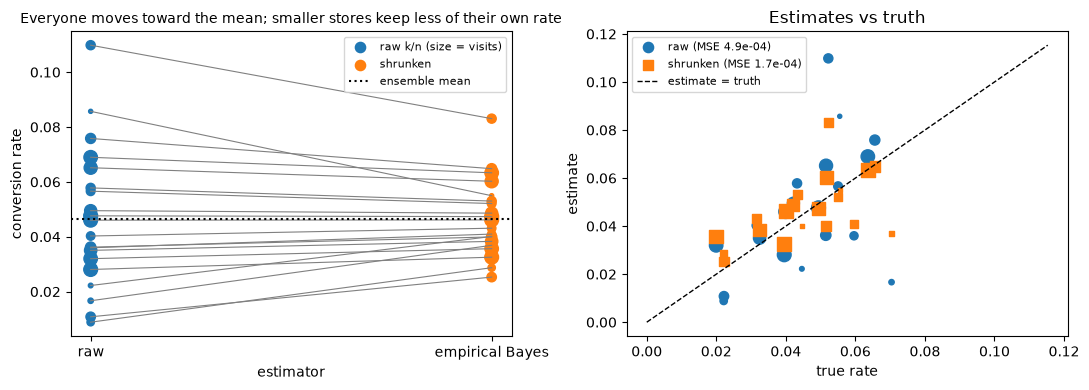


best store by raw rate:     #17 (raw 0.110, 173 visits, true 0.052)
best store by shrunken rate: #17 (shrunk 0.083, 173 visits, true 0.052)
truly best store:            #14 (true 0.070)

over 200 replications: median MSE ratio shrunken/raw = 0.55;  shrinkage helps in 89% of replications


In [23]:
rng = np.random.default_rng(11)
n_stores = 20

# --- synthetic ground truth: true conversion rates around 5%, very unequal traffic ---
true_rates = rng.beta(6, 114, size=n_stores)                 # mean 0.05, sd about 0.02
visits = rng.integers(20, 400, size=n_stores)
conversions = rng.binomial(visits, true_rates)
raw = conversions / visits

# --- empirical-Bayes Beta prior by the method of moments ---
m = raw.mean()
var_raw = raw.var(ddof=1)
sampling_noise = np.mean(raw * (1 - raw) / visits)             # average binomial variance of the raw rates
v_between = max(var_raw - sampling_noise, 1e-6)               # variance of the TRUE rates, net of noise
strength = m * (1 - m) / v_between - 1                        # a + b
a_eb, b_eb = m * strength, (1 - m) * strength
print(f"ensemble mean {m:.4f};  var of raw rates {var_raw:.6f} = between-store {v_between:.6f} + sampling noise {sampling_noise:.6f}")
print(f"empirical-Bayes prior: Beta({a_eb:.2f}, {b_eb:.2f})  ->  prior strength a + b = {strength:.1f} pseudo-visits")

# --- shrink every store toward the prior mean ---
shrunk = (a_eb + conversions) / (strength + visits)
weight_data = visits / (strength + visits)

mse_raw = np.mean((raw - true_rates) ** 2)
mse_shrunk = np.mean((shrunk - true_rates) ** 2)
mse_pooled = np.mean((m - true_rates) ** 2)
print(f"\nMSE vs true rates:  raw {mse_raw:.3e}   shrunken {mse_shrunk:.3e}   fully pooled (everyone = {m:.3f}) {mse_pooled:.3e}")
print(f"shrinkage cuts the MSE to {mse_shrunk / mse_raw:.0%} of the raw estimates'")

order = np.argsort(visits)
print(f"\n{'store':>5s} {'visits':>7s} {'conv':>5s} {'raw':>7s} {'shrunk':>7s} {'true':>7s} {'data weight':>12s}")
for i in order:
    print(f"{i:5d} {visits[i]:7d} {conversions[i]:5d} {raw[i]:7.3f} {shrunk[i]:7.3f} {true_rates[i]:7.3f} {weight_data[i]:12.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for i in range(n_stores):
    ax1.plot([0, 1], [raw[i], shrunk[i]], color="gray", lw=0.8)
ax1.scatter(np.zeros(n_stores), raw, s=visits / 4, label="raw k/n (size = visits)")
ax1.scatter(np.ones(n_stores), shrunk, s=visits / 4, label="shrunken")
ax1.axhline(m, color="k", ls=":", label="ensemble mean")
ax1.set_xticks([0, 1]); ax1.set_xticklabels(["raw", "empirical Bayes"]); ax1.set_xlabel("estimator"); ax1.set_ylabel("conversion rate")
ax1.set_title("Everyone moves toward the mean; smaller stores keep less of their own rate", fontsize=10); ax1.legend(fontsize=8)
ax2.scatter(true_rates, raw, s=visits / 4, label=f"raw (MSE {mse_raw:.1e})")
ax2.scatter(true_rates, shrunk, s=visits / 4, marker="s", label=f"shrunken (MSE {mse_shrunk:.1e})")
lims = [0, max(raw.max(), true_rates.max()) * 1.05]
ax2.plot(lims, lims, "k--", lw=1, label="estimate = truth"); ax2.set_xlabel("true rate"); ax2.set_ylabel("estimate"); ax2.set_title("Estimates vs truth"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

# --- ranking: which store is really the best? ---
print(f"\nbest store by raw rate:     #{np.argmax(raw)} (raw {raw.max():.3f}, {visits[np.argmax(raw)]} visits, true {true_rates[np.argmax(raw)]:.3f})")
print(f"best store by shrunken rate: #{np.argmax(shrunk)} (shrunk {shrunk.max():.3f}, {visits[np.argmax(shrunk)]} visits, true {true_rates[np.argmax(shrunk)]:.3f})")
print(f"truly best store:            #{np.argmax(true_rates)} (true {true_rates.max():.3f})")

# --- robustness: repeat the whole experiment 200 times ---
ratios = []
for rep in range(200):
    r = np.random.default_rng(1000 + rep)
    tr = r.beta(6, 114, size=n_stores); vi = r.integers(20, 400, size=n_stores); co = r.binomial(vi, tr); rw = co / vi
    mm = rw.mean(); vb = max(rw.var(ddof=1) - np.mean(rw * (1 - rw) / vi), 1e-6); st = mm * (1 - mm) / vb - 1
    sh = (mm * st + co) / (st + vi)
    ratios.append(np.mean((sh - tr) ** 2) / np.mean((rw - tr) ** 2))
ratios = np.array(ratios)
print(f"\nover 200 replications: median MSE ratio shrunken/raw = {np.median(ratios):.2f};  shrinkage helps in {np.mean(ratios < 1):.0%} of replications")

## Score

In [24]:
summary()


Score: 73/73 checks passed  🎉
